<a href="https://colab.research.google.com/github/inambaig24/TASKS/blob/main/NLP_Sentiment_Classification_TF_IDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NLP Sentiment Classification on Customer Reviews (TF-IDF)
### Google Colab Notebook — Task 4

**Objective:** Build a text-classification pipeline that labels customer/movie reviews as positive or negative.

**Workflow**
1. Load a sentiment review dataset.
2. Clean text (HTML tags, URLs, punctuation, lowercase, and stopwords).
3. Convert text into TF-IDF features.
4. Train and compare Multinomial Naive Bayes and Logistic Regression.
5. Evaluate accuracy, precision, recall, F1-score, and confusion matrices.
6. Test custom review phrases using `predict_sentiment()`.

**Dataset:** The notebook tries to load a small IMDb review dataset from a public source. If that fails, upload a CSV containing a review-text column and a sentiment/label column. This notebook is designed for binary positive/negative sentiment.

## 1. Install and import libraries

In [1]:
%pip -q install nltk scikit-learn pandas matplotlib

In [2]:
import re
import html
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load a review dataset
The preferred dataset is a public IMDb movie-review CSV. If the URL is unavailable, Colab will let you upload your own CSV. Your CSV should contain review text and a label such as `positive` / `negative` or `1` / `0`.

In [3]:
# Public IMDb dataset mirror (50,000 labeled reviews).
DATA_URL = "https://raw.githubusercontent.com/laxmimerit/All-CSV-ML-Data-Files-Download/master/IMDB-Dataset.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset loaded from public URL.")
except Exception as exc:
    print("Automatic download failed:", exc)
    from google.colab import files
    uploaded = files.upload()
    csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    if csv_name is None:
        raise ValueError("Please upload a CSV file containing review text and sentiment labels.")
    df = pd.read_csv(csv_name)

print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Dataset loaded from public URL.
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Columns: ['review', 'sentiment']


## 3. Identify text and sentiment columns
The code automatically detects common column names. If your CSV uses different names, set `TEXT_COL` and `LABEL_COL` manually in the first two lines below.

Usable rows: 49582


,text,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Class distribution:


,count
sentiment,
positive,24884
negative,24698


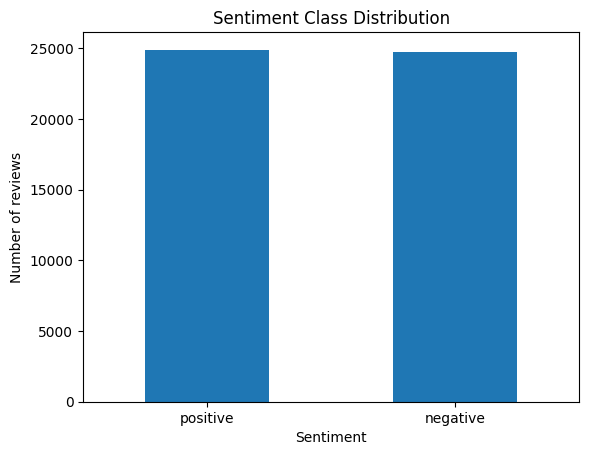

In [4]:
# If automatic detection selects the wrong columns, replace None with the exact column names.
TEXT_COL = None   # e.g. "review"
LABEL_COL = None  # e.g. "sentiment"

text_candidates = ["review", "text", "comment", "content", "reviews", "sentence"]
label_candidates = ["sentiment", "label", "polarity", "target", "class"]

if TEXT_COL is None:
    TEXT_COL = next((c for c in df.columns if c.lower().strip() in text_candidates), None)
if LABEL_COL is None:
    LABEL_COL = next((c for c in df.columns if c.lower().strip() in label_candidates), None)

if TEXT_COL is None or LABEL_COL is None:
    raise ValueError(
        "Could not automatically detect text/label columns. "
        "Set TEXT_COL and LABEL_COL in this cell. Available columns: "
        + str(df.columns.tolist())
    )

data = df[[TEXT_COL, LABEL_COL]].copy()
data.columns = ["text", "sentiment"]
data = data.dropna(subset=["text", "sentiment"])
data["text"] = data["text"].astype(str)
data["sentiment"] = data["sentiment"].astype(str).str.strip().str.lower()

# Normalize common sentiment labels to binary classes.
positive_labels = {"positive", "pos", "1", "true", "positive review"}
negative_labels = {"negative", "neg", "0", "false", "negative review"}

def normalize_label(value):
    if value in positive_labels:
        return "positive"
    if value in negative_labels:
        return "negative"
    return None

data["sentiment"] = data["sentiment"].map(normalize_label)
data = data.dropna(subset=["sentiment"]).drop_duplicates(subset=["text", "sentiment"])
data = data[data["text"].str.strip().ne("")].copy()

if data["sentiment"].nunique() != 2:
    raise ValueError(
        "Expected two sentiment classes (positive/negative or 1/0). "
        "Check your label values: " + str(df[LABEL_COL].value_counts().head(20).to_dict())
    )

print("Usable rows:", len(data))
display(data.head())
print("\nClass distribution:")
display(data["sentiment"].value_counts().to_frame("count"))
data["sentiment"].value_counts().plot(kind="bar", rot=0)
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.show()

## 4. Clean and preprocess text
This preprocessing removes HTML tags, URLs, punctuation, and extra spaces, and converts text to lowercase. Stopword removal is applied by TF-IDF to keep the pipeline concise and reproducible.

In [5]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)                 # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text) # URLs
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)                # punctuation/numbers
    text = re.sub(r"\s+", " ", text).strip()             # repeated spaces
    return text

data["clean_text"] = data["text"].apply(clean_text)
data = data[data["clean_text"].str.len() > 0].copy()

display(data[["text", "clean_text", "sentiment"]].head(5))
print("Rows after text cleaning:", len(data))

,text,clean_text,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive


Rows after text cleaning: 49582


## 5. Split into train and test sets
A stratified split keeps the positive/negative ratio similar in both sets. The test set is reserved for final evaluation.

In [6]:
X = data["clean_text"]
y = data["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))
print("\nTraining label distribution:")
display(y_train.value_counts().to_frame("count"))

Training reviews: 39665
Test reviews: 9917

Training label distribution:


,count
sentiment,
positive,19907
negative,19758


## 6. Train TF-IDF + Multinomial Naive Bayes and Logistic Regression
`TfidfVectorizer` learns vocabulary and inverse-document-frequency weights from the training data only. Each model is placed in a pipeline to prevent data leakage.

In [7]:
models = {
    "Multinomial Naive Bayes": Pipeline(steps=[
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline(steps=[
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

trained_models = {}
for name, model in models.items():
    print(f"Training {name} ...")
    model.fit(X_train, y_train)
    trained_models[name] = model
    print("Done.")

Training Multinomial Naive Bayes ...
Done.
Training Logistic Regression ...
Done.


## 7. Evaluate and compare models
Accuracy is the percentage of correct predictions. Precision, recall, and F1-score provide additional information about positive and negative predictions.

In [ ]:
results = []
test_probabilities = {}

for name, model in trained_models.items():
    predictions = model.predict(X_test)
    positive_index = list(model.named_steps["classifier"].classes_).index("positive")
    probabilities = model.predict_proba(X_test)[:, positive_index]
    test_probabilities[name] = probabilities

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, pos_label="positive", zero_division=0),
        "Recall": recall_score(y_test, predictions, pos_label="positive", zero_division=0),
        "F1-score": f1_score(y_test, predictions, pos_label="positive", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.style.format({
    "Accuracy": "{:.3f}", "Precision": "{:.3f}",
    "Recall": "{:.3f}", "F1-score": "{:.3f}"
}))

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
print("Best model by F1-score:", best_name)

In [ ]:
# Plot model metric comparison
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score"]
plot_df = results_df.set_index("Model")[metrics_to_plot]
ax = plot_df.plot(kind="bar", figsize=(10, 6), ylim=(0, 1), rot=10)
ax.set_title("Sentiment Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Classification report and confusion matrix
The confusion matrix shows correct and incorrect predictions for each sentiment class.

In [ ]:
best_predictions = best_model.predict(X_test)
print("Best model:", best_name)
print(classification_report(y_test, best_predictions, labels=["negative", "positive"], zero_division=0))

cm = confusion_matrix(y_test, best_predictions, labels=["negative", "positive"])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(values_format="d")
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

## 9. Interactive helper: test your own review
Run the cell and enter a review phrase to receive a positive/negative prediction and confidence estimate. The confidence is the model's predicted probability, not a guarantee.

In [ ]:
def predict_sentiment(review_text, model=best_model):
    cleaned = clean_text(review_text)
    if not cleaned:
        return {"sentiment": "unable to predict", "confidence": 0.0}

    prediction = model.predict([cleaned])[0]
    classes = list(model.named_steps["classifier"].classes_)
    probabilities = model.predict_proba([cleaned])[0]
    confidence = float(probabilities[classes.index(prediction)])

    return {
        "sentiment": prediction,
        "confidence": round(confidence, 4)
    }

# Try changing this example, or use the interactive input below.
examples = [
    "The product is excellent and works perfectly. I am very happy with it.",
    "Terrible quality. It stopped working after one day and I regret buying it."
]
for example in examples:
    print("Review:", example)
    print("Prediction:", predict_sentiment(example))
    print()

# Optional interactive input in Colab:
custom_review = input("Type a customer/movie review (or press Enter to skip): ").strip()
if custom_review:
    print(predict_sentiment(custom_review))

## 10. Show important TF-IDF terms for Logistic Regression (optional)
For a binary Logistic Regression model, positive coefficients indicate terms associated with the positive class and negative coefficients indicate terms associated with the negative class.

In [ ]:
if "Logistic Regression" in trained_models:
    lr_pipeline = trained_models["Logistic Regression"]
    vectorizer = lr_pipeline.named_steps["tfidf"]
    classifier = lr_pipeline.named_steps["classifier"]
    feature_names = np.array(vectorizer.get_feature_names_out())

    if len(classifier.classes_) == 2:
        coefficients = classifier.coef_[0]
        top_positive_idx = np.argsort(coefficients)[-10:][::-1]
        top_negative_idx = np.argsort(coefficients)[:10]

        print("Terms most associated with positive sentiment:")
        display(pd.DataFrame({
            "Term": feature_names[top_positive_idx],
            "Coefficient": coefficients[top_positive_idx]
        }))

        print("Terms most associated with negative sentiment:")
        display(pd.DataFrame({
            "Term": feature_names[top_negative_idx],
            "Coefficient": coefficients[top_negative_idx]
        }))

## 11. Save results
Save the comparison table as a CSV file. In Google Colab, uncomment the download lines if you want to download it to your computer.

In [ ]:
results_df.to_csv("sentiment_model_comparison.csv", index=False)
print("Saved sentiment_model_comparison.csv")

# Uncomment to download the result:
# from google.colab import files
# files.download("sentiment_model_comparison.csv")